Install Libraries and Import Packages

In [1]:
!pip install ucimlrepo -q

import pandas as pd
import numpy as np
import time, random
import matplotlib.pyplot as plt
from collections import defaultdict
from itertools import combinations
from ucimlrepo import fetch_ucirepo

Load Real Dataset (UCI Default of Credit Card Clients)

In [2]:
# UCI Machine Learning Repository, dataset id = 350 (30,000 real credit card customers)
data = fetch_ucirepo(id=350)
raw = data.data.features.copy()
raw["DEFAULT"] = data.data.targets.iloc[:, 0].values

raw.columns = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
               "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
               "BILL_1", "BILL_2", "BILL_3", "BILL_4", "BILL_5", "BILL_6",
               "PAYAMT_1", "PAYAMT_2", "PAYAMT_3", "PAYAMT_4", "PAYAMT_5", "PAYAMT_6",
               "DEFAULT"]

print("Real dataset shape:", raw.shape)
display(raw.head())

Real dataset shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_4,BILL_5,BILL_6,PAYAMT_1,PAYAMT_2,PAYAMT_3,PAYAMT_4,PAYAMT_5,PAYAMT_6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Convert Customer Records into Transactions (Item Baskets)

In [3]:
bill_cols = [f"BILL_{i}" for i in range(1, 7)]
pay_cols = [f"PAYAMT_{i}" for i in range(1, 7)]

# Derived financial indicators

# Credit utilization based on latest month's bill
raw["UTIL"] = (
    raw["BILL_1"].clip(lower=0) /
    raw["LIMIT_BAL"].replace(0, np.nan)
).fillna(0)

# Total positive outstanding bills over six months
total_bills = raw[bill_cols].clip(lower=0).sum(axis=1)

# Total positive payments over six months
total_payments = raw[pay_cols].clip(lower=0).sum(axis=1)

# Repayment ratio
raw["REPAY_RATIO"] = np.where(
    total_bills > 0,
    total_payments / total_bills,
    0
)

limit_cat = pd.qcut(raw["LIMIT_BAL"], 3, labels=["Low_Limit", "Mid_Limit", "High_Limit"]).astype(str).tolist()
age_cat = pd.cut(raw["AGE"], [0, 29, 45, 100],
                 labels=["Age_Under30", "Age_30_45", "Age_Above45"]).astype(str).tolist()

# Each customer = one transaction (basket of items)
records = raw.to_dict("records")
transactions = []
for i, r in enumerate(records):
    items = [limit_cat[i], age_cat[i]]
    for k in range(1, 7):
        if r[f"PAY_{k}"] >= 1:                 # payment delay in month k (M1 = most recent)
            items.append(f"Delay_M{k}")
    if r["PAY_1"] == -1:
        items.append("Paid_Duly_Recent")
    if r["UTIL"] > 0.8:
        items.append("Util_High")
    if r["REPAY_RATIO"] < 0.05:
        items.append("Low_Repayment")
    items.append("Default_Yes" if r["DEFAULT"] == 1 else "Default_No")
    transactions.append(sorted(items))

df = pd.DataFrame({"TID": range(1, len(transactions) + 1), "Items": transactions})
N = len(df)

# Risk-related behavioural indicators
risk_behavior_items = (
    [f"Delay_M{k}" for k in range(1, 7)]
    + ["Util_High", "Low_Repayment"]
)

# Default is an outcome, not a spending behaviour
outcome_item = "Default_Yes"

print("Total transactions (customers):", N)
display(df.head(10))

Total transactions (customers): 30000


,TID,Items
0,1,"[Age_Under30, Default_Yes, Delay_M1, Delay_M2,..."
1,2,"[Age_Under30, Default_Yes, Delay_M2, Delay_M6,..."
2,3,"[Age_30_45, Default_No, Mid_Limit]"
3,4,"[Age_30_45, Default_No, Low_Limit, Low_Repayme..."
4,5,"[Age_Above45, Default_No, Low_Limit, Paid_Duly..."
5,6,"[Age_30_45, Default_No, Low_Limit, Low_Repayme..."
6,7,"[Age_Under30, Default_No, High_Limit]"
7,8,"[Age_Under30, Default_No, Mid_Limit]"
8,9,"[Age_Under30, Default_No, Delay_M3, Mid_Limit]"
9,10,"[Age_30_45, Default_No, Low_Limit]"


Horizontal Format vs Vertical Format

In [4]:
# Horizontal format: TID -> Items
print("HORIZONTAL FORMAT (TID -> Items)")
display(df.head(5))

# Vertical format: Item -> TID-set
vertical = defaultdict(set)
for tid, items in zip(df["TID"], df["Items"]):
    for it in items:
        vertical[it].add(tid)

print("\nVERTICAL FORMAT (Item -> TID-set)  [first 5 TIDs only]")
vdf = pd.DataFrame({
    "Item": list(vertical.keys()),
    "Support_Count": [len(v) for v in vertical.values()],
    "TID_set (first 5)": [sorted(v)[:5] for v in vertical.values()],
}).sort_values("Support_Count", ascending=False).reset_index(drop=True)
display(vdf)

HORIZONTAL FORMAT (TID -> Items)


,TID,Items
0,1,"[Age_Under30, Default_Yes, Delay_M1, Delay_M2,..."
1,2,"[Age_Under30, Default_Yes, Delay_M2, Delay_M6,..."
2,3,"[Age_30_45, Default_No, Mid_Limit]"
3,4,"[Age_30_45, Default_No, Low_Limit, Low_Repayme..."
4,5,"[Age_Above45, Default_No, Low_Limit, Paid_Duly..."



VERTICAL FORMAT (Item -> TID-set)  [first 5 TIDs only]


,Item,Support_Count,TID_set (first 5)
0,Default_No,23364,"[3, 4, 5, 6, 7]"
1,Age_30_45,15713,"[3, 4, 6, 10, 11]"
2,Low_Limit,10799,"[1, 4, 5, 6, 10]"
3,Low_Repayment,10679,"[4, 6, 14, 15, 16]"
4,High_Limit,9622,"[7, 12, 13, 15, 18]"
5,Age_Under30,9618,"[1, 2, 7, 8, 9]"
6,Mid_Limit,9579,"[2, 3, 8, 9, 11]"
7,Util_High,7980,"[4, 6, 14, 16, 26]"
8,Delay_M1,6818,"[1, 14, 16, 19, 20]"
9,Default_Yes,6636,"[1, 2, 14, 17, 22]"


ECLAT Algorithm Implementation

In [5]:
import math

MIN_SUP_PCT = 0.05

# Minimum support count (rounded upward)
min_sup = math.ceil(MIN_SUP_PCT * N)

print("Minimum Support Percentage:", MIN_SUP_PCT * 100, "%")
print("Minimum Support Count:", min_sup)

def eclat(prefix, items, min_sup, freq):
    """
    ECLAT Algorithm using Vertical Data Format.

    prefix  : Current itemset
    items   : List of (item, TID-set)
    min_sup : Minimum support count
    freq    : Dictionary storing frequent itemsets
    """

    for i in range(len(items)):

        item, tids = items[i]

        # Generate new frequent itemset
        new_prefix = prefix + [item]

        # Store support count
        freq[frozenset(new_prefix)] = len(tids)

        suffix = []

        # Intersect TID sets of remaining items
        for j in range(i + 1, len(items)):

            other, o_tids = items[j]

            intersection = tids & o_tids

            # Check minimum support
            if len(intersection) >= min_sup:
                suffix.append((other, intersection))

        # Recursively generate larger itemsets
        if suffix:
            eclat(new_prefix, suffix, min_sup, freq)

start = time.perf_counter()
freq_items = {}
L1 = [(it, tids) for it, tids in vertical.items() if len(tids) >= min_sup]
L1.sort(key=lambda x: len(x[1]))
eclat([], L1, min_sup, freq_items)
eclat_time = time.perf_counter() - start

print(f"ECLAT time: {eclat_time:.4f} sec | Frequent itemsets found: {len(freq_items)}")

eclat_df = pd.DataFrame({
    "Itemset": [", ".join(sorted(k)) for k in freq_items],
    "Size": [len(k) for k in freq_items],
    "Support_Count": list(freq_items.values()),
    "Support_%": [round(v / N * 100, 2) for v in freq_items.values()],
}).sort_values(["Size", "Support_Count"], ascending=[False, False]).reset_index(drop=True)
display(eclat_df)

Minimum Support Percentage: 5.0 %
Minimum Support Count: 1500
ECLAT time: 0.1062 sec | Frequent itemsets found: 186


,Itemset,Size,Support_Count,Support_%
0,"Delay_M1, Delay_M2, Delay_M3, Delay_M4, Delay_M5",5,1600,5.33
1,"Delay_M1, Delay_M2, Delay_M3, Delay_M4",4,2065,6.88
2,"Default_No, Low_Limit, Low_Repayment, Util_High",4,1847,6.16
3,"Age_30_45, Default_No, Low_Repayment, Util_High",4,1804,6.01
4,"Delay_M1, Delay_M2, Delay_M3, Low_Repayment",4,1762,5.87
...,...,...,...,...
181,Delay_M2,1,4438,14.79
182,Delay_M3,1,4213,14.04
183,Delay_M4,1,3510,11.70
184,Delay_M6,1,3079,10.26


Frequent Itemset Analysis by Size:


,Size,Frequent_Itemsets,Average_Support,Maximum_Support
0,1,17,27.327059,77.88
1,2,85,10.297529,41.51
2,3,71,7.002394,18.04
3,4,12,5.674167,6.88
4,5,1,5.330000,5.33


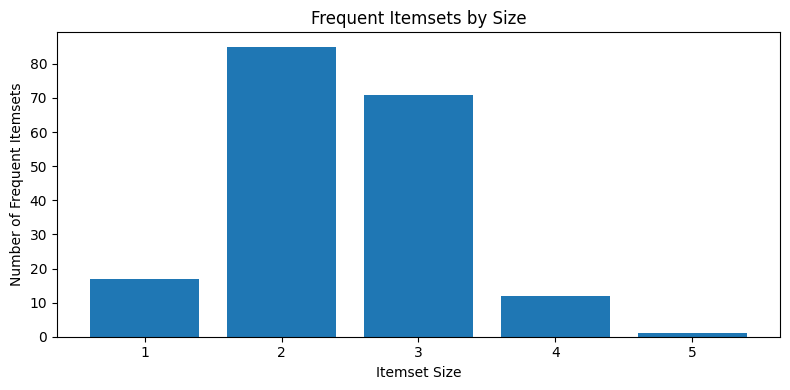

In [6]:
# Support distribution based on itemset size

size_analysis = (
    eclat_df.groupby("Size")
    .agg(
        Frequent_Itemsets=("Itemset", "count"),
        Average_Support=("Support_%", "mean"),
        Maximum_Support=("Support_%", "max")
    )
    .reset_index()
)

print("Frequent Itemset Analysis by Size:")

display(size_analysis)

# Visualization

plt.figure(figsize=(8, 4))

plt.bar(
    size_analysis["Size"],
    size_analysis["Frequent_Itemsets"]
)

plt.xlabel("Itemset Size")
plt.ylabel("Number of Frequent Itemsets")
plt.title("Frequent Itemsets by Size")

plt.xticks(size_analysis["Size"])

plt.tight_layout()
plt.show()

Risky Spending Patterns and Association Rules

In [7]:
# Identify frequent itemsets made only from at least two
# risky behavioural indicators.

risky_set = set(risk_behavior_items)

risky_patterns = {
    itemset: support
    for itemset, support in freq_items.items()
    if len(itemset) >= 2 and itemset.issubset(risky_set)
}

risky_df = pd.DataFrame([
    {
        "Itemset": ", ".join(sorted(itemset)),
        "Size": len(itemset),
        "Support_Count": support,
        "Support_%": round(support / N * 100, 2)
    }
    for itemset, support in risky_patterns.items()
], columns=["Itemset", "Size", "Support_Count", "Support_%"])

if not risky_df.empty:
    risky_df = risky_df.sort_values(
        "Support_Count", ascending=False
    ).reset_index(drop=True)

print("Frequent Risky Behaviour Patterns:")
display(risky_df.head(15))

# Association rules (Support, Confidence, Lift) from risky itemsets
# Association rules for risky behaviour and default outcome

rules = []

for itemset, sup in freq_items.items():

    if len(itemset) < 2:
        continue

    # Only itemsets containing Default_Yes
    if outcome_item not in itemset:
        continue

    # Remaining items must be risky behaviours
    risky_part = itemset - {outcome_item}

    if not risky_part.issubset(risky_set):
        continue

    # Generate rules with Default_Yes as consequent
    antecedent = frozenset(risky_part)
    consequent = frozenset({outcome_item})

    ante_tids = set.intersection(
        *(vertical[item] for item in antecedent)
    )

    conf = sup / len(ante_tids)

    lift = conf / (
        len(vertical[outcome_item]) / N
    )

    rules.append({
        "Antecedent": ", ".join(sorted(antecedent)),
        "Consequent": outcome_item,
        "Support": round(sup / N, 3),
        "Confidence": round(conf, 3),
        "Lift": round(lift, 2)
    })


rules_df = pd.DataFrame(rules, columns=["Antecedent", "Consequent", "Support", "Confidence", "Lift"])

if not rules_df.empty:

    rules_df = rules_df.sort_values(
        ["Lift", "Confidence"],
        ascending=False
    ).reset_index(drop=True)

print("Risk Behaviour → Default Association Rules:")

display(rules_df.head(10))


Frequent Risky Behaviour Patterns:


,Itemset,Size,Support_Count,Support_%
0,"Low_Repayment, Util_High",2,5257,17.52
1,"Delay_M1, Delay_M2",2,3991,13.30
2,"Delay_M1, Low_Repayment",2,3492,11.64
3,"Delay_M2, Delay_M3",2,2937,9.79
4,"Delay_M1, Delay_M3",2,2838,9.46
5,"Delay_M1, Delay_M2, Delay_M3",3,2737,9.12
6,"Delay_M3, Delay_M4",2,2589,8.63
7,"Delay_M2, Low_Repayment",2,2489,8.30
8,"Delay_M1, Delay_M2, Low_Repayment",3,2440,8.13
9,"Delay_M1, Delay_M4",2,2297,7.66


Risk Behaviour → Default Association Rules:


,Antecedent,Consequent,Support,Confidence,Lift
0,"Delay_M1, Delay_M4",Default_Yes,0.050,0.657,2.97
1,"Delay_M1, Delay_M2, Delay_M3",Default_Yes,0.058,0.638,2.88
2,"Delay_M1, Delay_M3",Default_Yes,0.059,0.628,2.84
3,"Delay_M2, Delay_M3",Default_Yes,0.061,0.623,2.82
4,"Delay_M3, Delay_M4",Default_Yes,0.052,0.601,2.72
5,"Delay_M1, Delay_M2",Default_Yes,0.077,0.578,2.61
6,"Delay_M1, Low_Repayment",Default_Yes,0.066,0.570,2.57
7,Delay_M2,Default_Yes,0.083,0.558,2.52
8,Delay_M5,Default_Yes,0.055,0.556,2.51
9,Delay_M4,Default_Yes,0.063,0.535,2.42


Visualization of Top Frequent Itemsets

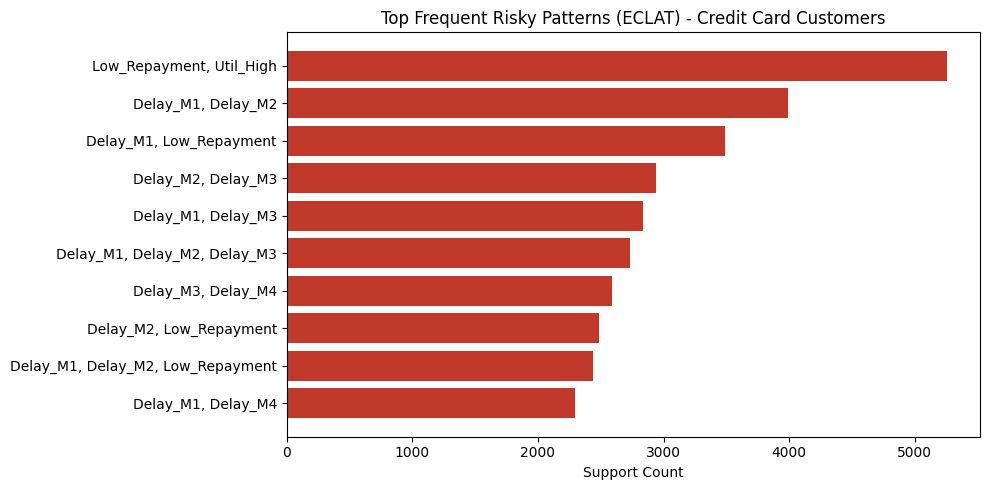

In [8]:
# Top risky itemsets (at least 2 risky items) by support count
top_risky = risky_df[risky_df["Size"] >= 2].sort_values("Support_Count", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_risky["Itemset"][::-1], top_risky["Support_Count"][::-1], color="#c0392b")
plt.xlabel("Support Count")
plt.title("Top Frequent Risky Patterns (ECLAT) - Credit Card Customers")
plt.tight_layout()
plt.show()

In [9]:
# Apriori Algorithm Implementation

from itertools import combinations

def apriori(transactions, min_sup):
    """
    Mine frequent itemsets using the Apriori algorithm.

    transactions: iterable of transactions (each transaction is an iterable of items)
    min_sup: minimum support count (integer)
    Returns: (frequent_itemsets, number_of_database_scans)
    """
    if min_sup < 1:
        raise ValueError("min_sup must be at least 1")

    transactions = [set(t) for t in transactions]

    freq = {}
    scans = 0

    # Generate frequent 1-itemsets
    item_counts = defaultdict(int)

    for transaction in transactions:
        for item in transaction:
            item_counts[frozenset([item])] += 1

    scans += 1

    current = {
        itemset: count
        for itemset, count in item_counts.items()
        if count >= min_sup
    }

    freq.update(current)
    k = 2

    # Generate larger frequent itemsets
    while current:
        previous = list(current.keys())
        candidates = set()

        # Candidate generation with Apriori subset pruning
        for i in range(len(previous)):
            for j in range(i + 1, len(previous)):
                candidate = previous[i] | previous[j]

                if len(candidate) != k:
                    continue

                # Every (k-1)-subset must be frequent
                if all(
                    frozenset(subset) in current
                    for subset in combinations(candidate, k - 1)
                ):
                    candidates.add(candidate)

        if not candidates:
            break

        candidate_counts = defaultdict(int)

        # Count candidate support by scanning the transactions
        for transaction in transactions:
            for candidate in candidates:
                if candidate.issubset(transaction):
                    candidate_counts[candidate] += 1

        scans += 1

        current = {
            itemset: count
            for itemset, count in candidate_counts.items()
            if count >= min_sup
        }

        freq.update(current)
        k += 1

    return freq, scans


Comparison, Horizontal (Apriori) vs Vertical (ECLAT)

In [10]:
# Compare ECLAT and Apriori on the same sample

SAMPLE_N = 5000

random.seed(42)
sample = random.sample(transactions, SAMPLE_N)

s_min_sup = math.ceil(MIN_SUP_PCT * SAMPLE_N)


# --------------------------------
# 1. ECLAT - Vertical Format
# --------------------------------

start = time.perf_counter()

# Convert horizontal transactions into vertical TID sets
s_vertical = defaultdict(set)

for tid, transaction in enumerate(sample):
    for item in transaction:
        s_vertical[item].add(tid)

# Generate frequent 1-itemsets
s_L1 = [
    (item, tids)
    for item, tids in s_vertical.items()
    if len(tids) >= s_min_sup
]

s_L1.sort(key=lambda x: len(x[1]))

# Apply ECLAT
s_freq = {}

eclat([], s_L1, s_min_sup, s_freq)

s_eclat_time = time.perf_counter() - start


# --------------------------------
# 2. Apriori - Horizontal Format
# --------------------------------

start = time.perf_counter()

apr_freq, apr_scans = apriori(sample, s_min_sup)

apr_time = time.perf_counter() - start


# --------------------------------
# 3. Performance Comparison\n# Note: timings are single-run observations and depend on hardware/runtime load.
# --------------------------------

print("Do both algorithms give identical results?",
      apr_freq == s_freq)

comparison = pd.DataFrame({

    "Parameter": [
        "Data Representation",
        "Database Scans",
        "Support Calculation",
        "Execution Time (sec)",
        "Frequent Itemsets Found"
    ],

    "Horizontal (Apriori)": [
        "TID -> Items",
        apr_scans,
        "Candidate counting",
        round(apr_time, 4),
        len(apr_freq)
    ],

    "Vertical (ECLAT)": [
        "Item -> TID-set",
        "1 initial conversion pass",
        "TID-set intersection",
        round(s_eclat_time, 4),
        len(s_freq)
    ]
})

display(comparison)


# Calculate speed ratio
if s_eclat_time > 0:

    speed_ratio = apr_time / s_eclat_time

    print(
        f"ECLAT / Apriori speed ratio: {speed_ratio:.2f}x"
    )

    if speed_ratio > 1:
        print("ECLAT is faster on this sample.")
    elif speed_ratio < 1:
        print("Apriori is faster on this sample.")
    else:
        print("Both algorithms have similar execution time.")

Do both algorithms give identical results? True


,Parameter,Horizontal (Apriori),Vertical (ECLAT)
0,Data Representation,TID -> Items,Item -> TID-set
1,Database Scans,5,1 initial conversion pass
2,Support Calculation,Candidate counting,TID-set intersection
3,Execution Time (sec),0.8975,0.0761
4,Frequent Itemsets Found,179,179


ECLAT / Apriori speed ratio: 11.79x
ECLAT is faster on this sample.


Default-Associated Association Rules

In [11]:
# Rules where the consequent is Default_Yes (behaviours associated with default)
default_rules = rules_df[rules_df["Consequent"] == "Default_Yes"] \
    .sort_values(["Lift", "Confidence"], ascending=False).reset_index(drop=True)

print("Top rules associated with Default_Yes:")
display(default_rules.head(10))

Top rules associated with Default_Yes:


,Antecedent,Consequent,Support,Confidence,Lift
0,"Delay_M1, Delay_M4",Default_Yes,0.050,0.657,2.97
1,"Delay_M1, Delay_M2, Delay_M3",Default_Yes,0.058,0.638,2.88
2,"Delay_M1, Delay_M3",Default_Yes,0.059,0.628,2.84
3,"Delay_M2, Delay_M3",Default_Yes,0.061,0.623,2.82
4,"Delay_M3, Delay_M4",Default_Yes,0.052,0.601,2.72
5,"Delay_M1, Delay_M2",Default_Yes,0.077,0.578,2.61
6,"Delay_M1, Low_Repayment",Default_Yes,0.066,0.570,2.57
7,Delay_M2,Default_Yes,0.083,0.558,2.52
8,Delay_M5,Default_Yes,0.055,0.556,2.51
9,Delay_M4,Default_Yes,0.063,0.535,2.42


In [12]:
# Final ECLAT Result Summary

print("=" * 50)
print("BANKING TRANSACTION ANALYSIS - ECLAT")
print("=" * 50)

print("Total Customers:", N)

print("Minimum Support:",
      MIN_SUP_PCT * 100, "%")

print("Minimum Support Count:", min_sup)

print("Total Frequent Itemsets:",
      len(freq_items))

print("Frequent Risky Patterns:",
      len(risky_df))

print("Total Association Rules:",
      len(rules_df))

if not risky_df.empty:

    print("\nTop Risky Pattern:")

    print(risky_df.iloc[0]["Itemset"])

if not rules_df.empty:

    print("\nTop Default-Associated Rule:")

    print(
        rules_df.iloc[0]["Antecedent"],
        "->",
        rules_df.iloc[0]["Consequent"]
    )

print("=" * 50)

BANKING TRANSACTION ANALYSIS - ECLAT
Total Customers: 30000
Minimum Support: 5.0 %
Minimum Support Count: 1500
Total Frequent Itemsets: 186
Frequent Risky Patterns: 54
Total Association Rules: 15

Top Risky Pattern:
Low_Repayment, Util_High

Top Default-Associated Rule:
Delay_M1, Delay_M4 -> Default_Yes
